## Modelagem: regressão da taxa de alfabetização municipal

### 0. Imports

In [1]:
import warnings
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from google.cloud import bigquery
from pathlib import Path
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import balanced_accuracy_score, mean_absolute_error, r2_score, roc_auc_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_validate
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor

### 1. Parâmetros

In [2]:
par_entrada = Path("../data/processed")
par_source_project = "tech-challenge-fase-2-505123"
par_alvo = "taxa_alfabetizacao"
par_grupo = "nome_mesorregiao"
par_rede_municipal = "3"
par_seed = 42
par_dobras = 5
par_iteracoes = 30
par_bootstrap = 2000
par_faixas_matriculas = [0, 200, 600, 2000, np.inf]
par_rotulos_matriculas = ["<200", "200-599", "600-1999", "2000+"]
par_cores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

client = bigquery.Client(project=par_source_project)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titlelocation": "left", "axes.titlesize": 11, "font.size": 9})
pd.set_option("display.max_columns", 50, "display.max_rows", 80, "display.float_format", "{:,.3f}".format)

### 2. Funções Auxiliares

In [3]:
def metricas(y, previsto):
    return {"rmse": root_mean_squared_error(y, previsto), "mae": mean_absolute_error(y, previsto), "r2": r2_score(y, previsto)}


def validar(nome, modelo, tempo=None):
    cv = cross_validate(modelo, X_treino, y_treino, groups=g_treino, cv=par_cv, return_train_score=True,
                        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"}, n_jobs=1)
    ajustado = clone(modelo).fit(X_treino, y_treino)
    return {"modelo": nome, "rmse_treino": -cv["train_rmse"].mean(), "rmse_cv": -cv["test_rmse"].mean(), "dp_cv": cv["test_rmse"].std(),
            "r2_cv": cv["test_r2"].mean(), **{f"{k}_validacao": v for k, v in metricas(y_validacao, ajustado.predict(X_validacao)).items()}}


def buscar(estimador, grade, n_iter=par_iteracoes):
    busca = RandomizedSearchCV(Pipeline([("prep", clone(preprocessador)), ("modelo", estimador)]), grade, n_iter=n_iter, cv=par_cv,
                               scoring="neg_root_mean_squared_error", random_state=par_seed, n_jobs=-1, refit=False)
    busca.fit(X_treino, y_treino, groups=g_treino)
    return Pipeline([("prep", clone(preprocessador)), ("modelo", estimador)]).set_params(**busca.best_params_), busca.best_params_


def sem_colunas(prep, remover, sem_indicadores=False):
    novo = clone(prep)
    novo.transformers = [(n, t, [c for c in cols if c not in remover]) for n, t, cols in novo.transformers
                         if not (sem_indicadores and n == "ausente")]
    return novo


def bootstrap_grupos(grupos, funcao, repeticoes=par_bootstrap, seed=par_seed):
    rng = np.random.default_rng(seed)
    posicoes = pd.Series(np.arange(len(grupos))).groupby(np.asarray(grupos)).apply(lambda s: s.values)
    valores = []
    for _ in range(repeticoes):
        indices = np.concatenate(posicoes.values[rng.integers(0, len(posicoes), len(posicoes))])
        valores.append(funcao(indices))
    return np.percentile(valores, [2.5, 50, 97.5])


def plot_barras(df, x, y, hue=None, titulo="", xlabel=None, referencia=None, fmt="%.2f", figsize=None):
    tab = df.pivot(index=x, columns=hue, values=y) if hue else df.set_index(x)[[y]]
    altura = max(2.4, .3 * len(tab) * (tab.shape[1] if hue else 1) + 1)
    ax = tab[::-1].plot.barh(figsize=figsize or (8, altura), color=par_cores[:tab.shape[1]], width=.8, edgecolor="white", linewidth=1.5, legend=bool(hue))
    if referencia is not None:
        ax.axvline(referencia, color="#52514e", linestyle="--", linewidth=1)
    if not hue:
        ax.bar_label(ax.containers[0], fmt=fmt, padding=3, fontsize=8)
    ax.grid(axis="y", visible=False)
    ax.set(title=titulo, xlabel=xlabel or y, ylabel="")
    plt.tight_layout()
    plt.show()


def plot_real_previsto(y, previsto, titulo=""):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.scatter(y, previsto, s=10, alpha=.45, color=par_cores[0], linewidths=0)
    ax.plot([0, 100], [0, 100], color="#52514e", linestyle="--", linewidth=1)
    ax.set(title=titulo, xlabel="taxa real", ylabel="taxa prevista")
    plt.tight_layout()
    plt.show()

### 3. Leitura de dados

In [4]:
df_municipio = pd.read_parquet(par_entrada / "base_municipio.parquet")
df_escoragem = pd.read_parquet(par_entrada / "base_municipio_escoragem_2025.parquet")
df_catalogo = pd.read_csv(par_entrada / "catalogo_features.csv")
preprocessador = joblib.load(par_entrada / "preprocessador_municipio.joblib")
par_features = df_catalogo.loc[df_catalogo["modelo_municipio"], "feature"].tolist()
par_familias = df_catalogo[df_catalogo["modelo_municipio"]].groupby("familia")["feature"].apply(list).to_dict()
df_municipio["faixa_matriculas"] = pd.cut(df_municipio["matriculas_anos_iniciais"], par_faixas_matriculas, labels=par_rotulos_matriculas, right=False)
df_municipio.groupby("split").agg(municipios=(par_alvo, "size"), mesorregioes=(par_grupo, "nunique"), ufs=("sigla_uf", "nunique"), media=(par_alvo, "mean"), dp=(par_alvo, "std"))

,municipios,mesorregioes,ufs,media,dp
split,,,,,
teste,1135,32,15,66.156,20.936
treino,2738,66,24,62.699,18.053
validacao,1359,34,19,61.997,19.521


### 4. Partições e validação

In [5]:
df_treino = df_municipio[df_municipio["split"] == "treino"]
df_validacao = df_municipio[df_municipio["split"] == "validacao"]
df_teste = df_municipio[df_municipio["split"] == "teste"]
X_treino, y_treino, g_treino = df_treino[par_features], df_treino[par_alvo].astype(float), df_treino[par_grupo]
X_validacao, y_validacao = df_validacao[par_features], df_validacao[par_alvo].astype(float)
X_teste, y_teste = df_teste[par_features], df_teste[par_alvo].astype(float)
par_cv = GroupKFold(n_splits=par_dobras)
assert not set(df_treino[par_grupo]) & set(df_validacao[par_grupo]) | set(df_treino[par_grupo]) & set(df_teste[par_grupo]) | set(df_validacao[par_grupo]) & set(df_teste[par_grupo])
print(X_treino.shape, X_validacao.shape, X_teste.shape)
resultados = {}
modelos = {}

(2738, 38) (1359, 38) (1135, 38)


**Decisão:** validar por mesorregião, com `GroupKFold`, usando as mesmas partições do modelo de aluno. A EDA mostrou forte autocorrelação espacial (I de Moran de 0,58, seção 8 da EDA), então separar municípios ao acaso colocaria vizinhos no treino e no teste e inflaria o resultado. O teste, com 1.135 municípios em 32 mesorregiões, fica fora de toda a escolha de modelo.

### 5. Referências simples

#### Média do treino

In [6]:
modelos["Média"] = Pipeline([("prep", clone(preprocessador)), ("modelo", DummyRegressor())])
resultados["Média"] = validar("Média", modelos["Média"])
resultados["Média"]

{'modelo': 'Média',
 'rmse_treino': np.float64(18.000550516016688),
 'rmse_cv': np.float64(18.45998579511938),
 'dp_cv': np.float64(0.8622924171469224),
 'r2_cv': np.float64(-0.15912802654187397),
 'rmse_validacao': 19.52602674159406,
 'mae_validacao': 16.4004288376438,
 'r2_validacao': -0.0012955036203297077}

#### Persistência: repetir a taxa de 2023

In [7]:
linhas = []
for treino, teste in par_cv.split(X_treino, y_treino, g_treino):
    mediana = X_treino.iloc[treino]["taxa_lag"].median()
    linhas.append(metricas(y_treino.iloc[teste], X_treino.iloc[teste]["taxa_lag"].fillna(mediana).astype(float)))
mediana_lag = X_treino["taxa_lag"].median()
resultados["Persistência"] = {"modelo": "Persistência", "rmse_treino": metricas(y_treino, X_treino["taxa_lag"].fillna(mediana_lag).astype(float))["rmse"],
                              "rmse_cv": np.mean([l["rmse"] for l in linhas]), "dp_cv": np.std([l["rmse"] for l in linhas]), "r2_cv": np.mean([l["r2"] for l in linhas]),
                              **{f"{k}_validacao": v for k, v in metricas(y_validacao, X_validacao["taxa_lag"].fillna(mediana_lag).astype(float)).items()}}
resultados["Persistência"]

{'modelo': 'Persistência',
 'rmse_treino': 16.39881713580849,
 'rmse_cv': np.float64(16.373467033873567),
 'dp_cv': np.float64(0.8778745102355535),
 'r2_cv': np.float64(0.09373232353062932),
 'rmse_validacao': 18.161592030702586,
 'mae_validacao': 13.429852895841957,
 'r2_validacao': 0.1337518144314076}

### 6. Benchmark: KNN

In [8]:
modelos["KNN"], par_knn = buscar(KNeighborsRegressor(), {"modelo__n_neighbors": randint(5, 150), "modelo__weights": ["uniform", "distance"], "modelo__p": [1, 2]})
resultados["KNN"] = validar("KNN", modelos["KNN"])
print(par_knn)
resultados["KNN"]

{'modelo__n_neighbors': 25, 'modelo__p': 1, 'modelo__weights': 'distance'}


{'modelo': 'KNN',
 'rmse_treino': np.float64(-0.0),
 'rmse_cv': np.float64(12.25549325400544),
 'dp_cv': np.float64(0.6104084947073688),
 'r2_cv': np.float64(0.4907971151956896),
 'rmse_validacao': 13.068215984362373,
 'mae_validacao': 10.148465883187376,
 'r2_validacao': 0.5514951810009479}

### 7. Modelos lineares

#### Regressão linear

In [9]:
modelos["Linear"] = Pipeline([("prep", clone(preprocessador)), ("modelo", LinearRegression())])
resultados["Linear"] = validar("Linear", modelos["Linear"])
resultados["Linear"]

{'modelo': 'Linear',
 'rmse_treino': np.float64(10.757934841207076),
 'rmse_cv': np.float64(11.604030382234168),
 'dp_cv': np.float64(0.8568169688763003),
 'r2_cv': np.float64(0.5440814095092398),
 'rmse_validacao': 12.658266928206354,
 'mae_validacao': 9.444411916185278,
 'r2_validacao': 0.5791929516525113}

#### Ridge

In [10]:
modelos["Ridge"], par_ridge = buscar(Ridge(), {"modelo__alpha": loguniform(1e-2, 1e4)})
resultados["Ridge"] = validar("Ridge", modelos["Ridge"])
print(par_ridge)
resultados["Ridge"]

{'modelo__alpha': np.float64(14.077923139972402)}


{'modelo': 'Ridge',
 'rmse_treino': np.float64(10.800728551048053),
 'rmse_cv': np.float64(11.40405166826242),
 'dp_cv': np.float64(0.9057990367495731),
 'r2_cv': np.float64(0.5591155267561414),
 'rmse_validacao': 12.603010936764088,
 'mae_validacao': 9.45272674269238,
 'r2_validacao': 0.5828587552925689}

#### Lasso

In [11]:
modelos["Lasso"], par_lasso = buscar(Lasso(max_iter=20000), {"modelo__alpha": loguniform(1e-3, 10)})
resultados["Lasso"] = validar("Lasso", modelos["Lasso"])
print(par_lasso)
resultados["Lasso"]

{'modelo__alpha': np.float64(0.06672367170464207)}


{'modelo': 'Lasso',
 'rmse_treino': np.float64(10.90349811155541),
 'rmse_cv': np.float64(11.287834714728817),
 'dp_cv': np.float64(0.8583676159591221),
 'r2_cv': np.float64(0.5683097084112899),
 'rmse_validacao': 12.613698998280432,
 'mae_validacao': 9.5725203956813,
 'r2_validacao': 0.5821509368503006}

### 8. Árvores

#### Árvore de decisão

In [12]:
modelos["Árvore"], par_arvore = buscar(DecisionTreeRegressor(random_state=par_seed),
                                       {"modelo__max_depth": randint(2, 15), "modelo__min_samples_leaf": randint(5, 100)})
resultados["Árvore"] = validar("Árvore", modelos["Árvore"])
print(par_arvore)
resultados["Árvore"]

{'modelo__max_depth': 8, 'modelo__min_samples_leaf': 79}


{'modelo': 'Árvore',
 'rmse_treino': np.float64(11.412772392525762),
 'rmse_cv': np.float64(12.897211992018654),
 'dp_cv': np.float64(0.7146280419835358),
 'r2_cv': np.float64(0.43812571500291464),
 'rmse_validacao': 14.01307693315919,
 'mae_validacao': 10.659453384439878,
 'r2_validacao': 0.48429478984338004}

#### Random Forest

In [13]:
modelos["Random Forest"], par_rf = buscar(RandomForestRegressor(n_estimators=300, random_state=par_seed, n_jobs=1),
                                          {"modelo__max_depth": randint(4, 25), "modelo__min_samples_leaf": randint(1, 30), "modelo__max_features": uniform(.1, .6)}, n_iter=15)
modelos["Random Forest"].set_params(modelo__n_jobs=-1)
resultados["Random Forest"] = validar("Random Forest", modelos["Random Forest"])
print(par_rf)
resultados["Random Forest"]

{'modelo__max_depth': 10, 'modelo__max_features': np.float64(0.5779257921161397), 'modelo__min_samples_leaf': 15}


{'modelo': 'Random Forest',
 'rmse_treino': np.float64(9.24593534609633),
 'rmse_cv': np.float64(11.601110478471707),
 'dp_cv': np.float64(0.8355415999392132),
 'r2_cv': np.float64(0.5452171475481937),
 'rmse_validacao': 12.721055879281609,
 'mae_validacao': 9.651433836837217,
 'r2_validacao': 0.5750079294717063}

### 9. Boosting

In [14]:
modelos["HistGB"], par_hgb = buscar(HistGradientBoostingRegressor(random_state=par_seed),
                                    {"modelo__learning_rate": loguniform(.01, .2), "modelo__max_iter": randint(100, 700), "modelo__max_leaf_nodes": randint(4, 40),
                                     "modelo__min_samples_leaf": randint(5, 80), "modelo__l2_regularization": loguniform(1e-3, 30)})
resultados["HistGB"] = validar("HistGB", modelos["HistGB"])
print(par_hgb)
resultados["HistGB"]

{'modelo__l2_regularization': np.float64(6.393310307063141), 'modelo__learning_rate': np.float64(0.03843694025082197), 'modelo__max_iter': 132, 'modelo__max_leaf_nodes': 26, 'modelo__min_samples_leaf': 66}


{'modelo': 'HistGB',
 'rmse_treino': np.float64(8.247154087230458),
 'rmse_cv': np.float64(11.652209478899747),
 'dp_cv': np.float64(0.8491649714598768),
 'r2_cv': np.float64(0.5419024773094068),
 'rmse_validacao': 12.624005222957688,
 'mae_validacao': 9.5519304619118,
 'r2_validacao': 0.581467837364251}

#### XGBoost

In [15]:
modelos["XGBoost"], par_xgb = buscar(xgb.XGBRegressor(random_state=par_seed, n_jobs=1, tree_method="hist"),
                                     {"modelo__learning_rate": loguniform(.01, .2), "modelo__n_estimators": randint(100, 700), "modelo__max_depth": randint(2, 8),
                                      "modelo__min_child_weight": randint(1, 40), "modelo__subsample": uniform(.5, .5), "modelo__colsample_bytree": uniform(.3, .7),
                                      "modelo__reg_lambda": loguniform(1e-2, 30)})
resultados["XGBoost"] = validar("XGBoost", modelos["XGBoost"])
print(par_xgb)
resultados["XGBoost"]

{'modelo__colsample_bytree': np.float64(0.35183125621386324), 'modelo__learning_rate': np.float64(0.029266761285490727), 'modelo__max_depth': 2, 'modelo__min_child_weight': 28, 'modelo__n_estimators': 234, 'modelo__reg_lambda': np.float64(9.029988685875853), 'modelo__subsample': np.float64(0.7247253370691017)}


{'modelo': 'XGBoost',
 'rmse_treino': np.float64(10.592857617540618),
 'rmse_cv': np.float64(11.5559482225096),
 'dp_cv': np.float64(0.7867611951973528),
 'r2_cv': np.float64(0.5481914316063714),
 'rmse_validacao': 12.804515496568335,
 'mae_validacao': 9.752356685725445,
 'r2_validacao': 0.5694131062650438}

#### LightGBM

In [16]:
modelos["LightGBM"], par_lgb = buscar(lgb.LGBMRegressor(random_state=par_seed, n_jobs=1, verbose=-1),
                                      {"modelo__learning_rate": loguniform(.01, .2), "modelo__n_estimators": randint(100, 700), "modelo__num_leaves": randint(4, 40),
                                       "modelo__min_child_samples": randint(5, 80), "modelo__subsample": uniform(.5, .5), "modelo__subsample_freq": [1],
                                       "modelo__colsample_bytree": uniform(.3, .7), "modelo__reg_lambda": loguniform(1e-2, 30)})
resultados["LightGBM"] = validar("LightGBM", modelos["LightGBM"])
print(par_lgb)
resultados["LightGBM"]

{'modelo__colsample_bytree': np.float64(0.46769332346688064), 'modelo__learning_rate': np.float64(0.015435211146627065), 'modelo__min_child_samples': 48, 'modelo__n_estimators': 515, 'modelo__num_leaves': 7, 'modelo__reg_lambda': np.float64(0.019104550307639058), 'modelo__subsample': np.float64(0.6848272280307022), 'modelo__subsample_freq': 1}


{'modelo': 'LightGBM',
 'rmse_treino': np.float64(9.574462709445175),
 'rmse_cv': np.float64(11.472226323109343),
 'dp_cv': np.float64(0.8369284780634766),
 'r2_cv': np.float64(0.5554871213176347),
 'rmse_validacao': 12.492419364918026,
 'mae_validacao': 9.454886073289472,
 'r2_validacao': 0.590147473900535}

### 10. Comparação

In [17]:
df_resultados = pd.DataFrame(resultados.values()).sort_values("rmse_cv").reset_index(drop=True)
rmse_knn = df_resultados.loc[df_resultados["modelo"] == "KNN", "rmse_cv"].item()
df_resultados["ganho_rmse_vs_knn_pct"] = 100 * (rmse_knn - df_resultados["rmse_cv"]) / rmse_knn
df_resultados["sobreajuste"] = df_resultados["rmse_cv"] - df_resultados["rmse_treino"]
df_resultados

,modelo,rmse_treino,rmse_cv,dp_cv,r2_cv,rmse_validacao,mae_validacao,r2_validacao,ganho_rmse_vs_knn_pct,sobreajuste
0,Lasso,10.903,11.288,0.858,0.568,12.614,9.573,0.582,7.896,0.384
1,Ridge,10.801,11.404,0.906,0.559,12.603,9.453,0.583,6.947,0.603
2,LightGBM,9.574,11.472,0.837,0.555,12.492,9.455,0.590,6.391,1.898
3,XGBoost,10.593,11.556,0.787,0.548,12.805,9.752,0.569,5.708,0.963
4,Random Forest,9.246,11.601,0.836,0.545,12.721,9.651,0.575,5.340,2.355
5,Linear,10.758,11.604,0.857,0.544,12.658,9.444,0.579,5.316,0.846
6,HistGB,8.247,11.652,0.849,0.542,12.624,9.552,0.581,4.923,3.405
7,KNN,-0.000,12.255,0.610,0.491,13.068,10.148,0.551,0.000,12.255
8,Árvore,11.413,12.897,0.715,0.438,14.013,10.659,0.484,-5.236,1.484
9,Persistência,16.399,16.373,0.878,0.094,18.162,13.430,0.134,-33.601,-0.025


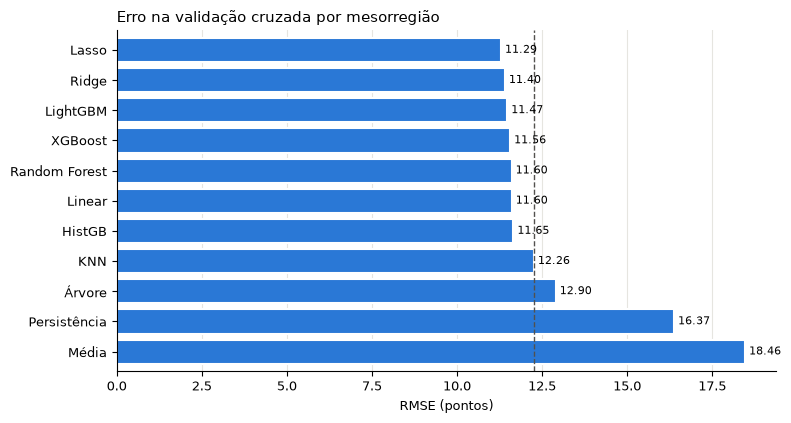

In [18]:
plot_barras(df_resultados, "modelo", "rmse_cv", titulo="Erro na validação cruzada por mesorregião", xlabel="RMSE (pontos)", referencia=rmse_knn)

In [19]:
par_melhor = df_resultados[~df_resultados["modelo"].isin(["Média", "Persistência"])].iloc[0]["modelo"]
print("Melhor modelo na validação cruzada:", par_melhor)
print("Melhor modelo na partição de validação:", df_resultados.sort_values("rmse_validacao").iloc[0]["modelo"])

Melhor modelo na validação cruzada: Lasso
Melhor modelo na partição de validação: LightGBM


**Decisão:** seguir com o Lasso (`alpha` de 0,0667).

- **Contra as referências:** o RMSE na validação cruzada foi de 11,29, contra 12,26 do KNN e 16,37 da persistência.
- **Contra os demais modelos:** Ridge (11,40) e LightGBM (11,47) ficam muito perto, dentro da variação entre dobras (cerca de 0,86), e o LightGBM é o melhor na partição de validação (12,49 contra 12,61). O empate favorece o modelo mais simples.
- **Sobreajuste:** o Lasso tem a menor diferença entre treino e validação cruzada entre os modelos (0,38, contra 1,90 do LightGBM e 3,41 do HistGB). A distância de 12,26 do KNN no treino não é informativa, pois `weights="distance"` memoriza a base.
- **Interpretação:** os coeficientes e a seleção de variáveis facilitam explicar o modelo a gestores.

### 11. Testes de variáveis

In [20]:
par_ablacao = {"Todas as features": ([], False),
               **{f"Sem {fam}": (cols, False) for fam, cols in par_familias.items()},
               "Sem UF": (["sigla_uf"], False),
               "Sem território": (par_familias["territorio_categorico"] + par_familias["territorio_numerico"], False),
               "Sem histórico e metas": (par_familias["historico"] + par_familias["metas"], False),
               "Sem indicadores de ausência": ([], True),
               "Sem presença e nº de avaliados": (["taxa_presenca_lag", "n_avaliados_lag"], False)}
linhas = []
for nome, (remover, sem_indicadores) in par_ablacao.items():
    pipe = clone(modelos[par_melhor]).set_params(prep=sem_colunas(preprocessador, remover, sem_indicadores))
    cv = cross_validate(pipe, X_treino, y_treino, groups=g_treino, cv=par_cv, scoring="neg_root_mean_squared_error")
    linhas.append({"cenario": nome, "rmse_cv": -cv["test_score"].mean()})
df_ablacao = pd.DataFrame(linhas)
df_ablacao["diferenca"] = df_ablacao["rmse_cv"] - df_ablacao.loc[0, "rmse_cv"]
df_ablacao.sort_values("rmse_cv")

,cenario,rmse_cv,diferenca
1,Sem docentes_turmas,11.266,-0.021
9,Sem territorio_numerico,11.269,-0.019
7,Sem socioeconomico,11.273,-0.015
5,Sem infraestrutura,11.278,-0.010
6,Sem metas,11.285,-0.003
2,Sem financiamento,11.287,-0.001
0,Todas as features,11.288,0.000
13,Sem indicadores de ausência,11.288,0.000
14,Sem presença e nº de avaliados,11.312,0.024
3,Sem fluxo_escolar,11.365,0.077


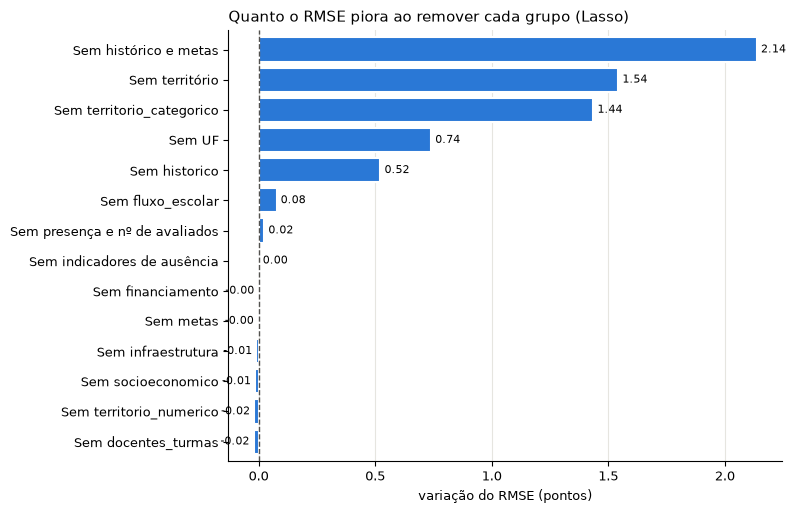

In [21]:
plot_barras(df_ablacao[df_ablacao["cenario"] != "Todas as features"].sort_values("diferenca", ascending=False), "cenario", "diferenca",
            titulo=f"Quanto o RMSE piora ao remover cada grupo ({par_melhor})", xlabel="variação do RMSE (pontos)", referencia=0)

### 12. Generalização mais exigente

#### Por UF: municípios de um estado nunca vistos

In [22]:
par_cv_uf = GroupKFold(n_splits=par_dobras)
df_todos_uf = pd.concat([df_treino, df_validacao])
pipes_uf = {"KNN": modelos["KNN"], par_melhor: modelos[par_melhor], "Linear": modelos["Linear"]}
linhas = []
for nome, pipe in pipes_uf.items():
    cv = cross_validate(pipe, df_todos_uf[par_features], df_todos_uf[par_alvo].astype(float), groups=df_todos_uf["sigla_uf"], cv=par_cv_uf,
                        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
    linhas.append({"modelo": nome, "rmse": -cv["test_rmse"].mean(), "r2": cv["test_r2"].mean()})
linhas.append({"modelo": "Persistência", "rmse": root_mean_squared_error(df_todos_uf[par_alvo], df_todos_uf["taxa_lag"].fillna(mediana_lag).astype(float)),
               "r2": r2_score(df_todos_uf[par_alvo], df_todos_uf["taxa_lag"].fillna(mediana_lag).astype(float))})
pd.DataFrame(linhas).sort_values("rmse")

,modelo,rmse,r2
1,Lasso,13.579,0.334
2,Linear,14.072,0.288
0,KNN,15.606,0.141
3,Persistência,17.004,0.160


#### Temporal: treinar com o alvo de 2023 e testar em 2024

In [23]:
par_sem_tempo = par_familias["historico"] + par_familias["metas"]
df_2023 = (pd.read_parquet(par_entrada / "base_aluno.parquet", filters=[("ano_alvo", "==", 2023), ("rede_id", "==", par_rede_municipal)])
           .drop_duplicates("id_municipio").drop(columns=["alfabetizado", "peso_amostral", "id_escola", "alunos_previstos_escola"]))
df_taxa_2023 = client.query(f"""select id_municipio, taxa_alfabetizacao from `{par_source_project}.gold.fato_indicador_municipio` where ano = 2023 and rede_id = "{par_rede_municipal}" """).to_dataframe()
df_2023 = df_2023.merge(df_taxa_2023, on="id_municipio")
df_2023[["meta_ano", "esforco_meta"]] = np.nan
print("Treino 2023:", df_2023.shape, "| UFs:", df_2023["sigla_uf"].nunique(), "| Teste 2024:", len(df_municipio))

Treino 2023: (4821, 45) | UFs: 23 | Teste 2024: 5232


In [24]:
linhas = []
for nome, pipe in {"KNN": modelos["KNN"], par_melhor: modelos[par_melhor], "Linear": modelos["Linear"]}.items():
    ajustado = clone(pipe).set_params(prep=sem_colunas(preprocessador, par_sem_tempo, True)).fit(df_2023[par_features], df_2023[par_alvo].astype(float))
    linhas.append({"modelo": nome, **metricas(df_municipio[par_alvo].astype(float), ajustado.predict(df_municipio[par_features]))})
linhas.append({"modelo": "Média 2023", **metricas(df_municipio[par_alvo].astype(float), np.full(len(df_municipio), df_2023[par_alvo].astype(float).mean()))})
pd.DataFrame(linhas).sort_values("rmse")

,modelo,rmse,mae,r2
0,KNN,14.885,11.524,0.396
1,Lasso,15.268,12.001,0.365
2,Linear,15.526,12.217,0.343
3,Média 2023,19.399,16.218,-0.026


**Decisão:** tratar 13,6 pontos de RMSE (R² de 0,33) como expectativa em estados nunca vistos e 15,3 pontos (R² de 0,36) como referência pessimista no teste temporal, que não tem histórico em 2023. Nesse teste, o KNN fica um pouco à frente do Lasso (14,9 contra 15,3), o que não muda a escolha, pois o uso real em 2025 conta com o histórico.

### 13. Avaliação final no teste

In [25]:
par_finalistas = ["KNN", "Linear", par_melhor]
X_ajuste = pd.concat([X_treino, X_validacao])
y_ajuste = pd.concat([y_treino, y_validacao])
finais = {n: clone(modelos[n]).fit(X_ajuste, y_ajuste) for n in par_finalistas}
previsoes_teste = {n: m.predict(X_teste) for n, m in finais.items()}
previsoes_teste["Persistência"] = X_teste["taxa_lag"].fillna(y_ajuste.median()).astype(float).values
df_teste_final = pd.DataFrame([{"modelo": n, **metricas(y_teste, p)} for n, p in previsoes_teste.items()]).sort_values("rmse")
df_teste_final

,modelo,rmse,mae,r2
2,Lasso,11.269,8.346,0.710
1,Linear,11.281,8.427,0.709
0,KNN,12.072,9.130,0.667
3,Persistência,16.078,11.494,0.410


**O ganho sobre o KNN é real? Intervalo de 95% por bootstrap de mesorregiões**

In [26]:
y_array = y_teste.values
ganho_knn = bootstrap_grupos(df_teste[par_grupo].values, lambda i: root_mean_squared_error(y_array[i], previsoes_teste["KNN"][i]) - root_mean_squared_error(y_array[i], previsoes_teste[par_melhor][i]))
ganho_persistencia = bootstrap_grupos(df_teste[par_grupo].values, lambda i: root_mean_squared_error(y_array[i], previsoes_teste["Persistência"][i]) - root_mean_squared_error(y_array[i], previsoes_teste[par_melhor][i]))
pd.DataFrame([ganho_knn, ganho_persistencia], columns=["p2.5", "mediana", "p97.5"], index=["KNN - melhor", "Persistência - melhor"])

,p2.5,mediana,p97.5
KNN - melhor,0.387,0.804,1.243
Persistência - melhor,2.358,4.702,6.858


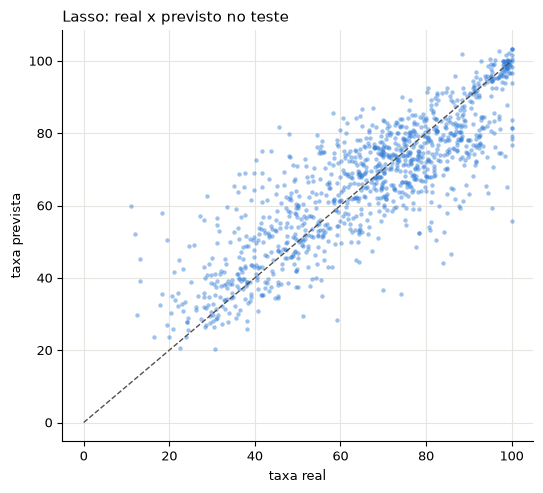

In [27]:
plot_real_previsto(y_teste, previsoes_teste[par_melhor], titulo=f"{par_melhor}: real x previsto no teste")

**Erro por segmento**

In [28]:
df_erro = df_teste.assign(previsto=previsoes_teste[par_melhor], previsto_knn=previsoes_teste["KNN"])
df_erro["erro_abs"] = (df_erro["previsto"] - df_erro[par_alvo]).abs()
df_erro["erro_abs_knn"] = (df_erro["previsto_knn"] - df_erro[par_alvo]).abs()
df_erro["vies"] = df_erro["previsto"] - df_erro[par_alvo]
pd.concat({c: df_erro.groupby(c, observed=True).agg(municipios=("erro_abs", "size"), mae=("erro_abs", "mean"), mae_knn=("erro_abs_knn", "mean"), vies=("vies", "mean"))
           for c in ["nome_regiao", "faixa_matriculas"]})

municipios    mae  mae_knn   vies
nome_regiao      Centro-Oeste           7  8.107   12.662  2.370
                 Nordeste             452  7.621    8.998  0.340
                 Norte                100  8.027    7.939 -4.392
                 Sudeste              306  9.417    9.583 -0.094
                 Sul                  270  8.472    9.186  1.816
faixa_matriculas <200                 103 13.238   14.149  1.289
                 200-599              367 10.035   10.276  0.775
                 600-1999             444  7.360    8.495 -0.189
                 2000+                221  5.245    6.160 -0.637

In [29]:
df_erro.groupby("sigla_uf").agg(municipios=("erro_abs", "size"), mae=("erro_abs", "mean"), vies=("vies", "mean")).query("municipios >= 20").sort_values("mae", ascending=False)

,municipios,mae,vies
sigla_uf,,,
PI,62,14.372,-0.975
RS,69,11.198,2.087
SP,52,10.504,-1.244
AL,26,10.140,-1.718
MA,112,9.894,-2.370
MG,242,9.335,0.241
SC,83,7.670,0.434
PR,118,7.443,2.630
PA,89,7.427,-4.338


**Da taxa prevista à meta de 2024**

In [30]:
linhas = []
y_meta = df_teste["atingiu_meta"].values
for nome, previsto in previsoes_teste.items():
    folga = previsto - df_teste["meta_ano"].astype(float).values
    linhas.append({"modelo": nome, "auc": roc_auc_score(y_meta, folga), "acuracia_balanceada": balanced_accuracy_score(y_meta, folga >= 0)})
pd.DataFrame(linhas).sort_values("auc", ascending=False)

,modelo,auc,acuracia_balanceada
2,Lasso,0.802,0.717
1,Linear,0.794,0.701
0,KNN,0.775,0.699
3,Persistência,0.575,0.553


**Decisão:** o Lasso segue como modelo final para prever a taxa e, por comparação com a meta, o alcance dela.

- **Desempenho no teste:** RMSE de 11,27, MAE de 8,35 e R² de 0,71, contra RMSE de 16,08 da persistência.
- **O ganho é real:** o intervalo de 95% por bootstrap de mesorregiões não inclui zero, tanto sobre o KNN (0,80, de 0,39 a 1,24) quanto sobre a persistência (4,70, de 2,36 a 6,86). A diferença para a regressão linear é mínima (11,27 contra 11,28).
- **Equidade do erro:** o MAE cai de 13,2 pontos em redes com menos de 200 matrículas para 5,2 nas maiores, e vai de 3,8 no CE a 14,4 no PI. O viés mais visível é no Norte (-4,4 pontos). Por isso, municípios pequenos precisam de faixa de confiança e revisão antes de qualquer ação.
- **Metas de 2024:** comparar a taxa prevista com a meta alcança AUC de 0,80, contra 0,57 da persistência.

### 14. Interpretabilidade

#### Importância por permutação (teste)

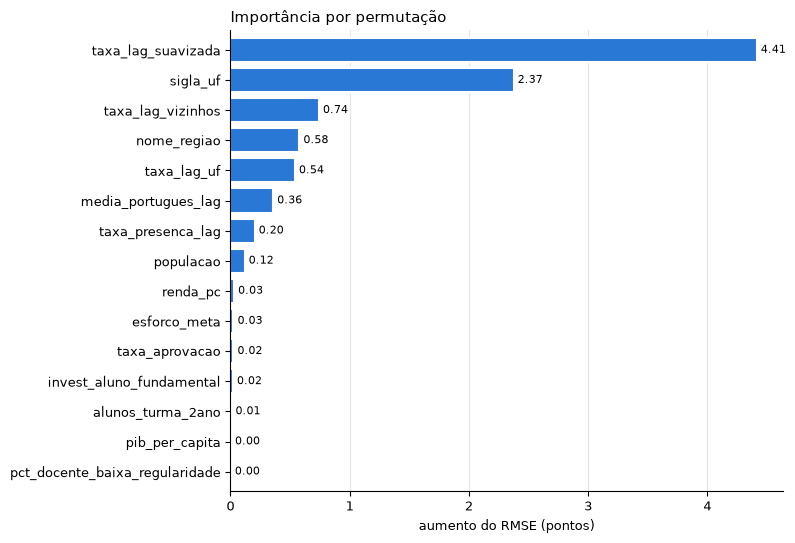

In [31]:
imp = permutation_importance(finais[par_melhor], X_teste, y_teste, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=par_seed, n_jobs=1)
df_importancia = pd.DataFrame({"feature": par_features, "aumento_rmse": imp.importances_mean, "dp": imp.importances_std}).sort_values("aumento_rmse", ascending=False)
plot_barras(df_importancia.head(15), "feature", "aumento_rmse", titulo="Importância por permutação", xlabel="aumento do RMSE (pontos)")

#### SHAP

Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


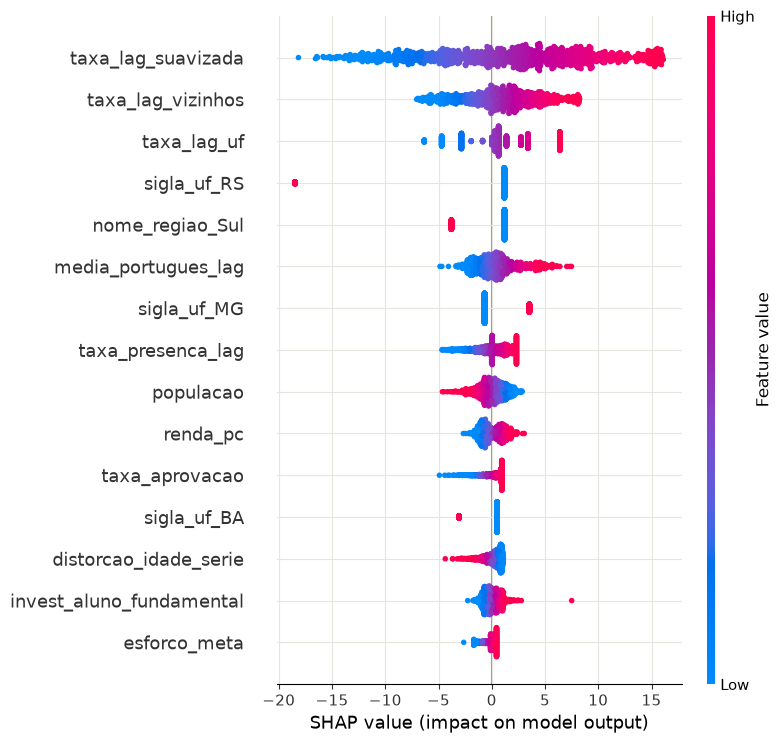

In [32]:
prep_final = finais[par_melhor].named_steps["prep"]
modelo_final = finais[par_melhor].named_steps["modelo"]
X_teste_prep = pd.DataFrame(prep_final.transform(X_teste), columns=[c.split("__")[1].replace("missingindicator_", "ausente_") for c in prep_final.get_feature_names_out()]).astype(float)
valores_shap = shap.Explainer(modelo_final, X_teste_prep.sample(min(300, len(X_teste_prep)), random_state=par_seed))(X_teste_prep)
shap.summary_plot(valores_shap, X_teste_prep, max_display=15, show=False)
plt.tight_layout()
plt.show()

In [33]:
pd.Series(np.abs(valores_shap.values).mean(axis=0), index=X_teste_prep.columns, name="shap_medio_abs").sort_values(ascending=False).head(15).to_frame()

,shap_medio_abs
taxa_lag_suavizada,6.705
taxa_lag_vizinhos,2.861
taxa_lag_uf,2.436
sigla_uf_RS,2.230
nome_regiao_Sul,1.815
media_portugues_lag,1.499
sigla_uf_MG,1.282
taxa_presenca_lag,1.252
populacao,0.988
renda_pc,0.892


### 15. Previsão das metas de 2025

In [34]:
modelo_producao = clone(modelos[par_melhor]).fit(df_municipio[par_features], df_municipio[par_alvo].astype(float))
df_2025 = df_escoragem.copy()
df_2025["taxa_prevista_2025"] = np.clip(modelo_producao.predict(df_2025[par_features]), 0, 100)
df_2025["folga_meta_2025"] = df_2025["taxa_prevista_2025"] - df_2025["meta_ano"].astype(float)
df_2025["atinge_meta_previsto"] = df_2025["folga_meta_2025"] >= 0
print("% previsto para atingir:", round(100 * df_2025["atinge_meta_previsto"].mean(), 1), "| municípios:", len(df_2025))
df_2025.groupby("sigla_uf").agg(municipios=("id_municipio", "size"), taxa_2024=("taxa_lag", "mean"), prevista=("taxa_prevista_2025", "mean"), meta=("meta_ano", "mean"),
                                pct_atinge=("atinge_meta_previsto", lambda s: 100 * s.mean())).sort_values("pct_atinge")

% previsto para atingir: 57.2 | municípios: 5352


,municipios,taxa_2024,prevista,meta,pct_atinge
sigla_uf,,,,,
RS,441,52.937,39.209,72.786,0.227
BA,398,36.646,39.084,50.218,6.784
PA,142,48.833,49.925,56.629,14.085
AM,55,45.005,46.518,55.991,14.545
RJ,92,58.736,59.836,63.505,21.739
AC,22,43.500,46.570,49.912,27.273
PR,398,74.039,73.759,75.473,31.658
SC,254,69.092,69.283,70.670,35.433
SE,75,36.447,43.412,43.899,37.333


In [35]:
df_2025.sort_values("folga_meta_2025").head(15)[["nome_municipio", "sigla_uf", "taxa_lag", "taxa_prevista_2025", "meta_ano", "folga_meta_2025"]]

,nome_municipio,sigla_uf,taxa_lag,taxa_prevista_2025,meta_ano,folga_meta_2025
4737,Canela,RS,42.200,28.925,79.060,-50.135
5037,Cerrito,RS,39.800,27.981,76.560,-48.579
4839,Sentinela do Sul,RS,23.500,27.735,75.700,-47.965
4868,Coronel Bicaco,RS,36.000,31.539,79.430,-47.891
4665,Pantano Grande,RS,25.700,27.530,74.820,-47.290
4909,Sapiranga,RS,41.100,28.422,74.990,-46.568
4954,São Marcos,RS,38.300,33.652,80.000,-46.348
4755,Gravataí,RS,41.000,22.601,68.910,-46.309
4740,São Sepé,RS,49.700,33.997,80.000,-46.003
4689,Pedro Osório,RS,22.300,25.674,71.610,-45.936


**Conclusão:** o Lasso prevê bem a taxa municipal, mas se apoia sobretudo no histórico e no território, e a previsão de 2025 herda o choque de 2024.

- **O que explica a previsão:** `taxa_lag_suavizada` lidera o SHAP (6,7 pontos), seguida de `taxa_lag_vizinhos` e `taxa_lag_uf`. Retirar histórico e metas aumenta o RMSE em 2,14 pontos, e retirar o território, em 1,54. Cada família de contexto muda o erro em menos de 0,08 ponto.
- **Limite principal:** o coeficiente do RS descreve a queda de 2024, que já está na taxa defasada. Assim, o modelo prevê 39,2% para o RS em 2025, abaixo dos 52,9% observados em 2024, e só 0,2% dos municípios gaúchos atingiriam a meta. Com um único par de anos não dá para saber se a queda se repete, e por isso o notebook 5 compara este cenário com um sem território.
- **Uso:** ordenar municípios por risco e distância da meta, sempre com intervalo e sem interpretar coeficientes como efeito causal.

### 16. Salvar artefatos

In [36]:
joblib.dump(modelo_producao, par_entrada / "modelo_taxa_municipal.joblib")
df_resultados.to_csv(par_entrada / "resultados_modelos.csv", index=False)
df_2025[["id_municipio", "nome_municipio", "sigla_uf", "taxa_lag", "taxa_prevista_2025", "meta_ano", "folga_meta_2025", "atinge_meta_previsto"]].to_csv(par_entrada / "previsoes_2025.csv", index=False)